In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid"); sns.set_palette("deep")
file_path = "cleaned_dataset.csv"  # Update if your CSV is stored elsewhere
data = pd.read_csv(file_path)
score_cols = ["Math_Score", "Reading_Score", "Writing_Score"]
print("Dataset shape:", data.shape)
display(data.head())

Dataset shape: (1001, 8)


,Gender,Race_Ethnicity,Parental_Education,Lunch_Type,Test_Preparation,Math_Score,Reading_Score,Writing_Score
0,female,group d,some college,free/reduced,none,60,66,70
1,female,group d,some college,standard,none,79,86,81
2,female,group c,bachelor's degree,free/reduced,none,50,60,59
3,female,group b,high school,standard,completed,68,83,78
4,female,group c,associate's degree,standard,none,64,64,70


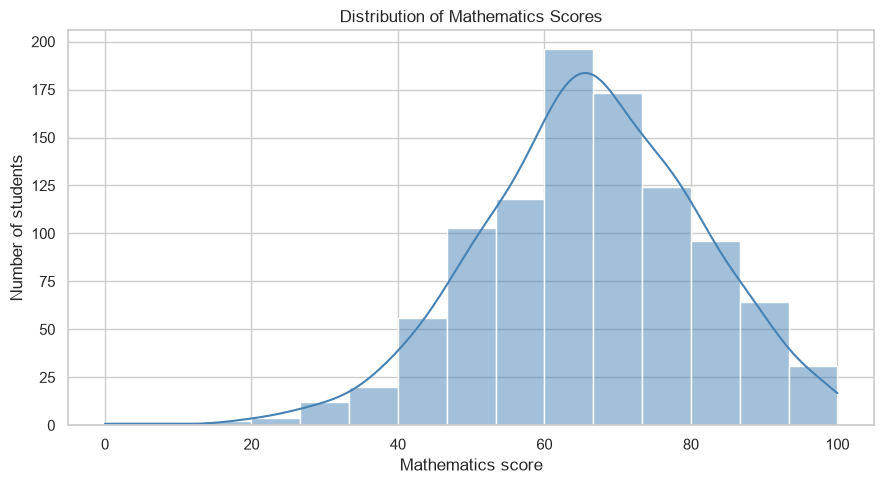

In [2]:
#Histogram – Mathematics score distribution
plt.figure(figsize=(9, 5))
sns.histplot(data=data, x="Math_Score", bins=15, kde=True, color="steelblue")
plt.title("Distribution of Mathematics Scores")
plt.xlabel("Mathematics score")
plt.ylabel("Number of students")
plt.tight_layout()

plt.savefig('visualization_01.png', dpi=300, bbox_inches='tight')

plt.show()

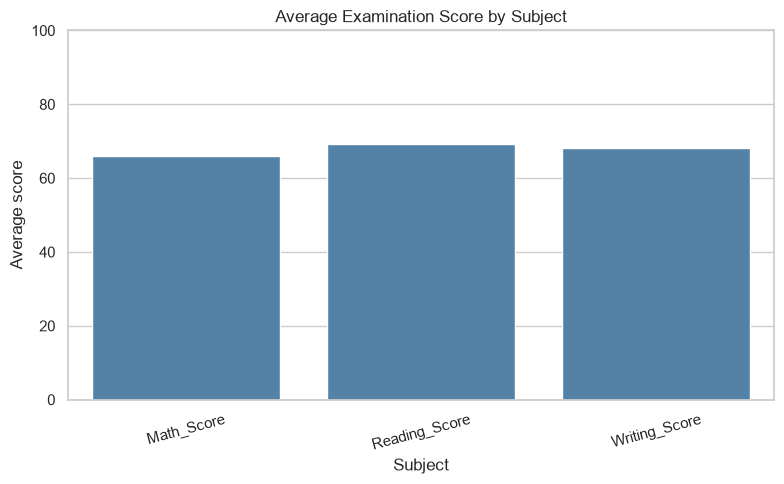

In [3]:
#Bar chart – Average score by subject
subject_means = data[["Math_Score", "Reading_Score", "Writing_Score"]].mean()
plt.figure(figsize=(8, 5))
sns.barplot(x=subject_means.index, y=subject_means.values, color="steelblue")
plt.title("Average Examination Score by Subject")
plt.xlabel("Subject")
plt.ylabel("Average score")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig('visualization_02.png', dpi=300, bbox_inches='tight')

plt.show()

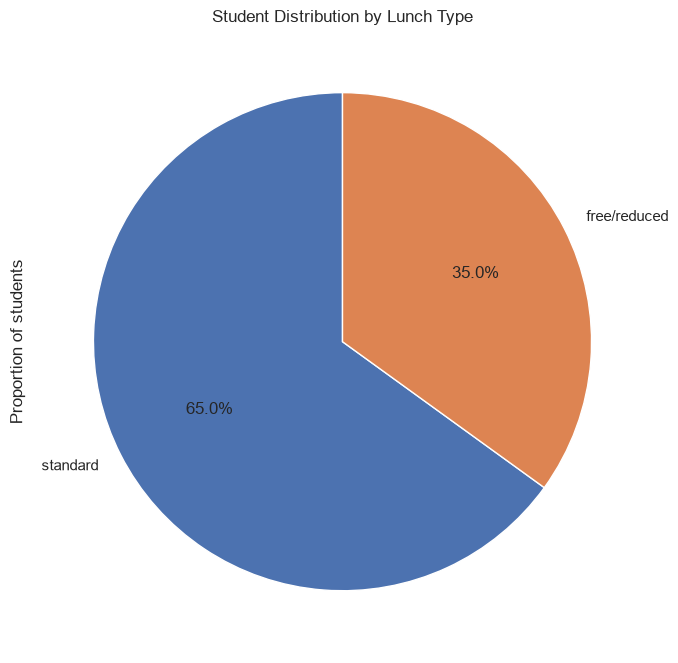

In [4]:
#Pie chart – Lunch type composition
lunch_counts = data["Lunch_Type"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(lunch_counts.values, labels=lunch_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Student Distribution by Lunch Type")
plt.ylabel("Proportion of students")
plt.tight_layout()
plt.savefig('visualization_03.png', dpi=300, bbox_inches='tight')
plt.show()

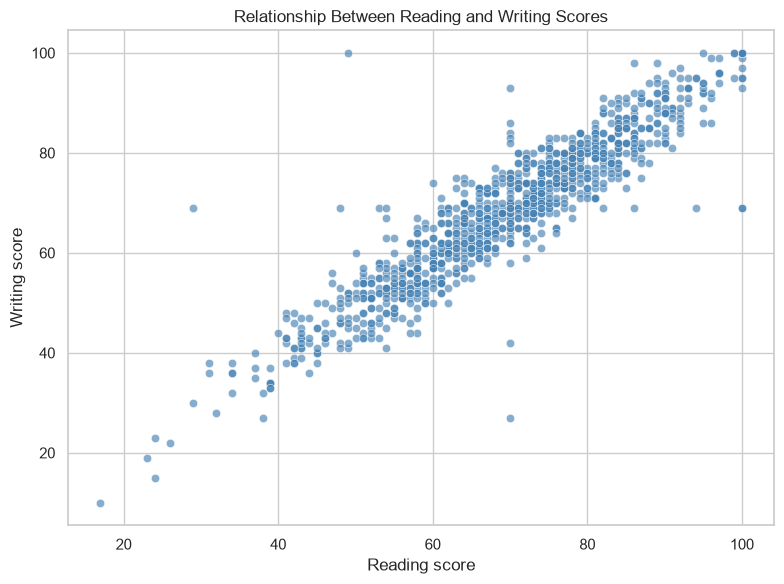

In [5]:
#Scatter plot – Reading versus writing scores
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data, x="Reading_Score", y="Writing_Score", alpha=0.65, color="steelblue")
plt.title("Relationship Between Reading and Writing Scores")
plt.xlabel("Reading score")
plt.ylabel("Writing score")
plt.tight_layout()
plt.savefig('visualization_04.png', dpi=300, bbox_inches='tight')
plt.show()


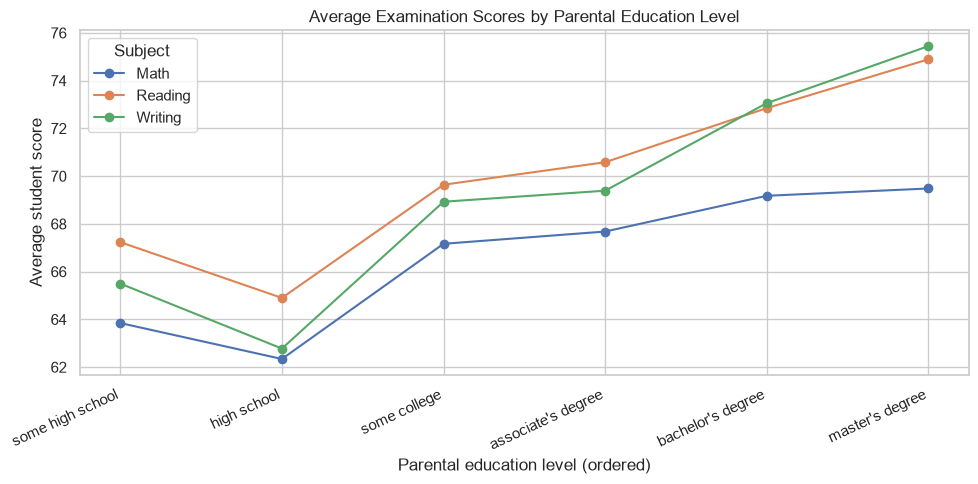

In [6]:
#Line chart – Average scores by parental education
education_order = ["some high school", "high school", "some college", "associate's degree", "bachelor's degree", "master's degree"]
ordered = data.copy()
ordered["Parental_Education"] = pd.Categorical(ordered["Parental_Education"], categories=education_order, ordered=True)
edu_means = ordered.groupby("Parental_Education", observed=False)[["Math_Score", "Reading_Score", "Writing_Score"]].mean()
plt.figure(figsize=(10, 5))
for col in ["Math_Score", "Reading_Score", "Writing_Score"]:
    plt.plot(edu_means.index.astype(str), edu_means[col], marker="o", label=col.replace("_Score", ""))
plt.title("Average Examination Scores by Parental Education Level")
plt.xlabel("Parental education level (ordered)")
plt.ylabel("Average student score")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Subject")
plt.tight_layout()
plt.savefig('visualization_05.png', dpi=300, bbox_inches='tight')
plt.show()

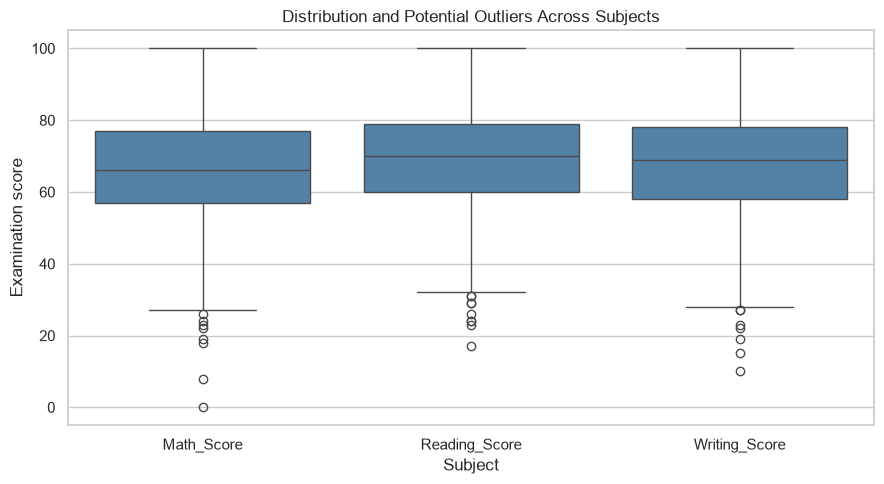

In [7]:
#Box plot – Score spread and potential outliers
long_scores = data[["Math_Score", "Reading_Score", "Writing_Score"]].melt(var_name="Subject", value_name="Score")
plt.figure(figsize=(9, 5))
sns.boxplot(data=long_scores, x="Subject", y="Score", color="steelblue")
plt.title("Distribution and Potential Outliers Across Subjects")
plt.xlabel("Subject")
plt.ylabel("Examination score")
plt.tight_layout()
plt.savefig('visualization_06.png', dpi=300, bbox_inches='tight')
plt.show()

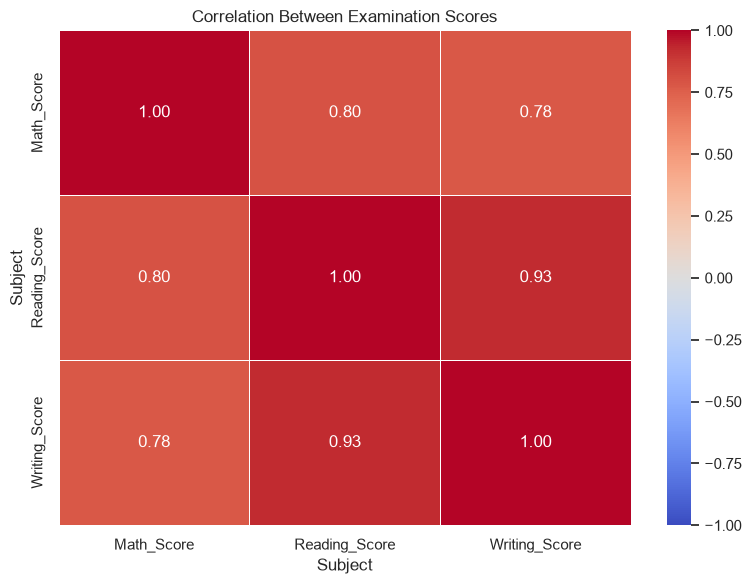

In [8]:
#Correlation heatmap – Relationships among scores
corr = data[["Math_Score", "Reading_Score", "Writing_Score"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Correlation Between Examination Scores")
plt.xlabel("Subject")
plt.ylabel("Subject")
plt.tight_layout()
plt.savefig('visualization_07.png', dpi=300, bbox_inches='tight')
plt.show()

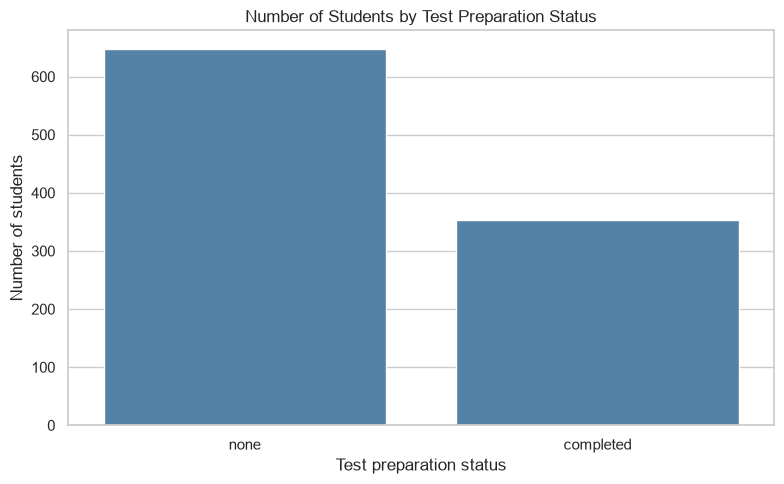

In [9]:
#Count plot – Test preparation status
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="Test_Preparation", order=data["Test_Preparation"].value_counts().index, color="steelblue")
plt.title("Number of Students by Test Preparation Status")
plt.xlabel("Test preparation status")
plt.ylabel("Number of students")
plt.tight_layout()
plt.savefig('visualization_08.png', dpi=300, bbox_inches='tight')
plt.show()

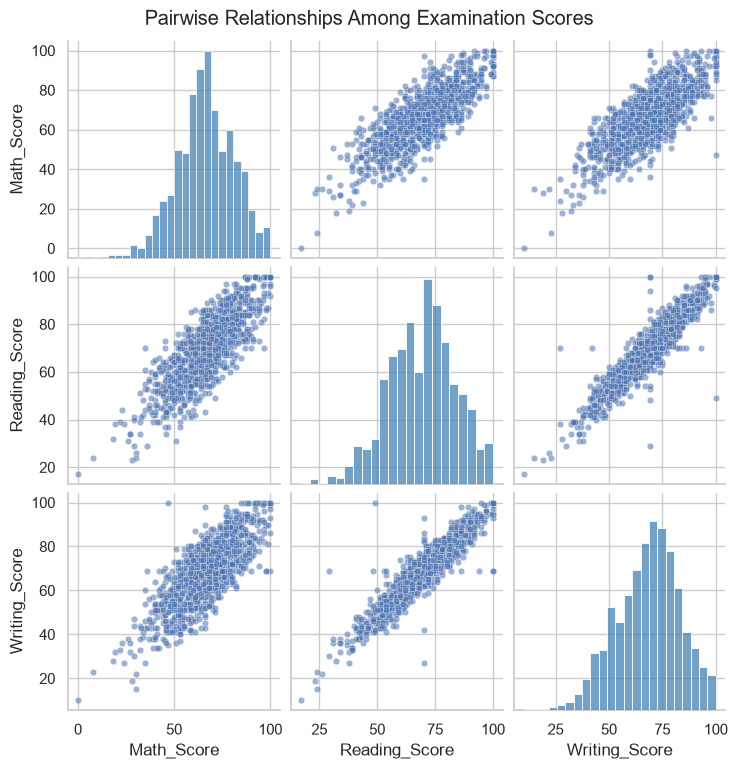

In [10]:
#Pair plot – Pairwise score relationships
pair = sns.pairplot(data=data, vars=["Math_Score", "Reading_Score", "Writing_Score"], diag_kind="hist", plot_kws={"alpha": 0.55, "s": 22}, diag_kws={"color": "steelblue"})
pair.fig.suptitle("Pairwise Relationships Among Examination Scores", y=1.02)
plt.savefig('visualization_09.png', dpi=300, bbox_inches='tight')
plt.show()

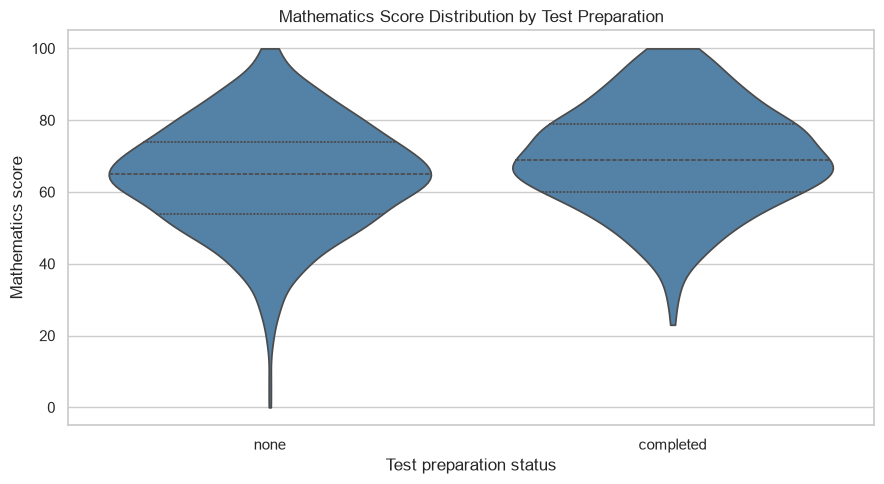

In [11]:
#Violin plot – Mathematics scores by test preparation
plt.figure(figsize=(9, 5))
sns.violinplot(data=data, x="Test_Preparation", y="Math_Score", inner="quartile", cut=0, color="steelblue")
plt.title("Mathematics Score Distribution by Test Preparation")
plt.xlabel("Test preparation status")
plt.ylabel("Mathematics score")
plt.tight_layout()
plt.savefig('visualization_10.png', dpi=300, bbox_inches='tight')
plt.show()